# Initial Set Up

## Install dependencies

In [1]:
!pip -q install transformers datasets accelerate

## Load Dataset and Classifier

In [2]:
import torch
from datasets import load_dataset
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1

# SST-2 dataset
dataset = load_dataset("nyu-mll/glue", "sst2")

# Fixed pretrained sentiment classifier
classifier = pipeline(
    "text-classification",
    model="distilbert/distilbert-base-uncased-finetuned-sst-2-english",
    device=device
)

print(dataset)
print("Device:", "GPU" if device == 0 else "CPU")

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  148kB            

... (7 outputs left out)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 872
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1821
    })
})
Device: GPU


## Verify Predictions

In [3]:
reviews = [
    "The movie was slow and predictable.",
    "The movie was engaging and beautifully written.",
    "The acting was terrible, but the soundtrack was excellent."
]

for review in reviews:
    prediction = classifier(review, truncation=True)[0]

    print("Review:", review)
    print("Prediction:", prediction["label"])
    print("Confidence:", round(prediction["score"], 4))
    print("-" * 60)

Review: The movie was slow and predictable.
Prediction: NEGATIVE
Confidence: 0.9998
------------------------------------------------------------
Review: The movie was engaging and beautifully written.
Prediction: POSITIVE
Confidence: 0.9999
------------------------------------------------------------
Review: The acting was terrible, but the soundtrack was excellent.
Prediction: POSITIVE
Confidence: 0.9998
------------------------------------------------------------


## Install dependenices for auxillary LLM

In [4]:
!pip -q install -U transformers accelerate bitsandbytes

## Load LLM (which will generate counterfactuals)

In [5]:
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"

if not torch.cuda.is_available():
    raise RuntimeError(
        "Please enable a GPU in Colab before loading this model."
    )

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

llm = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    device_map="auto"
)

llm.eval()

print("LLM loaded successfully!")

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

LLM loaded successfully!


## Test Counterfactutal Generation

In [6]:
def generate_counterfactual(
    review,
    target_label,
    max_new_tokens=100
):
    prompt = f"""Rewrite the review so that its sentiment is {target_label}.

            Preserve the original meaning and change as little text as possible.
            Return only the rewritten review.

            Original review: {review}
            Rewritten review:"""

    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(llm.device)

    with torch.no_grad():
        output = llm.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    new_tokens = output[0, inputs["input_ids"].shape[1]:]

    return tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    ).strip()


review = "The movie was slow and predictable."

candidate = generate_counterfactual(
    review,
    target_label="positive"
)

print("Original:", review)
print("Counterfactual:", candidate)
print("Classifier result:", classifier(candidate)[0])

Original: The movie was slow and predictable.
Counterfactual: The movie was slow and predictable, but it had its moments.
Classifier result: {'label': 'POSITIVE', 'score': 0.9954278469085693}


## Define Measurement Functions

| Metric                 | How it is measured                                         |
| ---------------------- | ---------------------------------------------------------- |
| Validity               | Whether the classifier predicts the requested target label |
| Edit distance          | Word-level edits between the original and generated text   |
| Relative edit distance | Word-level edit distance divided by original word count    |
| Generation latency     | Time taken to generate the candidate                       |
| Token usage            | Prompt tokens and generated tokens                         |
| Classifier confidence  | Confidence in the predicted label                          |
| LLM calls              | One generation call per example                            |





In [7]:
import time
import torch
import pandas as pd
from datasets import load_dataset

def word_edit_distance(original, candidate):
    """Levenshtein edit distance measured in words."""
    a = original.lower().split()
    b = candidate.lower().split()

    dp = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]

    for i in range(len(a) + 1):
        dp[i][0] = i
    for j in range(len(b) + 1):
        dp[0][j] = j

    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            cost = 0 if a[i - 1] == b[j - 1] else 1
            dp[i][j] = min(
                dp[i - 1][j] + 1,       # deletion
                dp[i][j - 1] + 1,       # insertion
                dp[i - 1][j - 1] + cost # substitution
            )

    return dp[-1][-1]


def predict_sentiment(text):
    result = classifier(text, truncation=True)[0]
    return result["label"].upper(), result["score"]


# One-shot Generations

In [8]:
def generate_one_shot_measured(original, target_label):
    prompt = f"""Rewrite the review so its sentiment is {target_label}.
              Preserve its original meaning and change as little as possible.
              Return only the rewritten review.

              Original review: {original}
              Rewritten review:"""

    messages = [{"role": "user", "content": prompt}]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(llm.device)

    prompt_tokens = inputs["input_ids"].shape[1]

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.no_grad():
        output = llm.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    latency = time.perf_counter() - start

    generated_ids = output[0, prompt_tokens:]
    candidate = tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()

    return {
        "candidate": candidate,
        "prompt_tokens": prompt_tokens,
        "generated_tokens": len(generated_ids),
        "generation_seconds": latency
    }

## Run one-shot generation on 50 examples

In [9]:
N = 50
validation_data = dataset["validation"].select(range(N))

results = []

for i, example in enumerate(validation_data):
    original = example["sentence"]

    # Determine the source label using the fixed classifier.
    original_label, original_confidence = predict_sentiment(original)

    # Target the opposite label.
    target_label = (
        "POSITIVE" if original_label == "NEGATIVE"
        else "NEGATIVE"
    )

    # Exactly one generation attempt; no repair.
    generation = generate_one_shot_measured(
        original, target_label
    )

    candidate = generation["candidate"]

    # Verify the generated candidate.
    predicted_label, confidence = predict_sentiment(candidate)

    edit_distance = word_edit_distance(original, candidate)
    original_word_count = max(len(original.split()), 1)

    results.append({
        "id": i,
        "original": original,
        "original_label": original_label,
        "target_label": target_label,
        "candidate": candidate,
        "predicted_label": predicted_label,
        "valid": predicted_label == target_label,
        "confidence": confidence,
        "edit_distance_words": edit_distance,
        "relative_edit_distance": edit_distance / original_word_count,
        "generation_seconds": generation["generation_seconds"],
        "prompt_tokens": generation["prompt_tokens"],
        "generated_tokens": generation["generated_tokens"],
        "llm_calls": 1
    })

    if (i + 1) % 10 == 0:
        print(f"Completed {i + 1}/{N} examples")

df = pd.DataFrame(results)

print("\nFirst 5 results:")
display(df.head())

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Completed 10/50 examples
Completed 20/50 examples
Completed 30/50 examples
Completed 40/50 examples
Completed 50/50 examples

First 5 results:


,id,original,original_label,target_label,candidate,predicted_label,valid,confidence,edit_distance_words,relative_edit_distance,generation_seconds,prompt_tokens,generated_tokens,llm_calls
0,0,it 's a charming and often affecting journey .,POSITIVE,NEGATIVE,it's a charming and often affecting journey.,POSITIVE,False,0.999884,4,0.444444,0.888146,79,10,1
1,1,unflinchingly bleak and desperate,NEGATIVE,POSITIVE,unflinchingly bleak and desperate,NEGATIVE,False,0.998970,0,0.000000,0.684929,76,8,1
2,2,allows us to hope that nolan is poised to emba...,POSITIVE,NEGATIVE,denies us hope that Nolan is poised to embark ...,POSITIVE,False,0.994063,5,0.250000,1.758337,90,22,1
3,3,"the acting , costumes , music , cinematography...",POSITIVE,NEGATIVE,"the acting, costumes, music, cinematography, a...",NEGATIVE,True,0.999788,12,0.600000,1.924113,92,24,1
4,4,"it 's slow -- very , very slow .",NEGATIVE,POSITIVE,"it's slow -- very, very slow.",NEGATIVE,False,0.999689,6,0.666667,0.873704,79,10,1


## Calculate the baseline metrics

### Summary

In [10]:
summary = pd.DataFrame([{
    "Examples": len(df),
    "Validity (%)": 100 * df["valid"].mean(),
    "Mean edit distance (words)": df["edit_distance_words"].mean(),
    "Mean relative edit distance": df["relative_edit_distance"].mean(),
    "Mean generation time (s)": df["generation_seconds"].mean(),
    "Total generation time (s)": df["generation_seconds"].sum(),
    "Mean prompt tokens": df["prompt_tokens"].mean(),
    "Mean generated tokens": df["generated_tokens"].mean(),
    "Total LLM calls": df["llm_calls"].sum()
}])

display(summary.round(4))

,Examples,Validity (%),Mean edit distance (words),Mean relative edit distance,Mean generation time (s),Total generation time (s),Mean prompt tokens,Mean generated tokens,Total LLM calls
0,50,46.0,9.28,0.4922,1.8742,93.7086,90.42,23.3,50


### Inspect failures

In [11]:
failures = df[~df["valid"]][
    [
        "original",
        "target_label",
        "candidate",
        "predicted_label",
        "edit_distance_words"
    ]
]

print(f"Failed counterfactuals: {len(failures)}/{len(df)}")
display(failures.head(10))

Failed counterfactuals: 27/50


,original,target_label,candidate,predicted_label,edit_distance_words
0,it 's a charming and often affecting journey .,NEGATIVE,it's a charming and often affecting journey.,POSITIVE,4
1,unflinchingly bleak and desperate,POSITIVE,unflinchingly bleak and desperate,NEGATIVE,0
2,allows us to hope that nolan is poised to emba...,NEGATIVE,denies us hope that Nolan is poised to embark ...,POSITIVE,5
4,"it 's slow -- very , very slow .",POSITIVE,"it's slow -- very, very slow.",NEGATIVE,6
5,although laced with humor and a few fanciful t...,NEGATIVE,although laced with humor and a few fanciful t...,POSITIVE,0
6,a sometimes tedious film .,POSITIVE,a somewhat tedious film.,NEGATIVE,3
8,you do n't have to know about music to appreci...,NEGATIVE,"Even if you don't know about music, you still ...",POSITIVE,13
9,"in exactly 89 minutes , most of which passed a...",POSITIVE,"In exactly 89 minutes, most of which felt like...",NEGATIVE,20
11,it takes a strange kind of laziness to waste t...,POSITIVE,It shows a strange kind of laziness to waste t...,NEGATIVE,11
12,... the film suffers from a lack of humor ( so...,POSITIVE,... the film lacks humor (something needed to ...,NEGATIVE,10


### Save the experiment results

In [12]:
df.to_csv("one_shot_results.csv", index=False)
summary.to_csv("one_shot_summary.csv", index=False)

print("Saved one_shot_results.csv and one_shot_summary.csv")

Saved one_shot_results.csv and one_shot_summary.csv


#### Added one more measurement (Mead edit distance between valid and failed only)

In [13]:
valid_df = df[df["valid"]]
failed_df = df[~df["valid"]]

print("Valid candidates:", len(valid_df))
print("Failed candidates:", len(failed_df))

if len(valid_df) > 0:
    print(
        "Mean edit distance (valid only):",
        round(valid_df["edit_distance_words"].mean(), 4)
    )

if len(failed_df) > 0:
    print(
        "Mean edit distance (failed only):",
        round(failed_df["edit_distance_words"].mean(), 4)
    )

Valid candidates: 23
Failed candidates: 27
Mean edit distance (valid only): 10.5652
Mean edit distance (failed only): 8.1852


# Multi-Candidate Selection

In [14]:
K = 5
TEMPERATURE = 0.9
TOP_P = 0.9
MAX_NEW_TOKENS = 100

def generate_multiple_candidates(original, target_label, k=K):
    prompt = f"""Rewrite the review so its sentiment is {target_label}.

            Preserve the original meaning and change as little as possible.
            Return only the rewritten review.

            Original review: {original}
            Rewritten review:"""

    messages = [{"role": "user", "content": prompt}]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to(llm.device)

    prompt_tokens = inputs["input_ids"].shape[1]

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.no_grad():
        outputs = llm.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=True,
            temperature=TEMPERATURE,
            top_p=TOP_P,
            num_return_sequences=k,
            pad_token_id=tokenizer.eos_token_id
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    candidates = []

    for output in outputs:
        generated_ids = output[prompt_tokens:]
        text = tokenizer.decode(
            generated_ids,
            skip_special_tokens=True
        ).strip()

        candidates.append({
            "candidate": text,
            "prompt_tokens": prompt_tokens,
            "generated_tokens": len(generated_ids)
        })

    return candidates, elapsed


print(f"Configured candidates per review: {K}")
print(f"Maximum candidate generations: {len(df) * K}")

Configured candidates per review: 5
Maximum candidate generations: 250


## Run the Multi-Candidate Selection on the same 50 reviews

In [15]:
candidate_records = []
selected_records = []

for _, row in df.iterrows():
    original = row["original"]
    target = row["target_label"]
    example_id = row["id"]

    candidates, batch_seconds = generate_multiple_candidates(
        original, target, k=K
    )

    example_candidates = []

    for j, item in enumerate(candidates):
        text = item["candidate"]

        pred_label, confidence = predict_sentiment(text)
        valid = pred_label == target
        distance = word_edit_distance(original, text)

        # For this binary classifier, estimate target-label
        # confidence from the predicted class and its score.
        target_confidence = (
            confidence if valid else 1.0 - confidence
        )

        record = {
            "id": example_id,
            "candidate_id": j + 1,
            "original": original,
            "target_label": target,
            "candidate": text,
            "predicted_label": pred_label,
            "valid": valid,
            "confidence": confidence,
            "target_confidence": target_confidence,
            "edit_distance_words": distance,
            "relative_edit_distance": (
                distance / max(len(original.split()), 1)
            ),
            "prompt_tokens": item["prompt_tokens"],
            "generated_tokens": item["generated_tokens"],
            "generation_batch_seconds": batch_seconds
        }

        candidate_records.append(record)
        example_candidates.append(record)

    # Prefer the valid candidate with minimum edit distance.
    valid_candidates = [
        c for c in example_candidates if c["valid"]
    ]

    if valid_candidates:
        selected = min(
            valid_candidates,
            key=lambda c: c["edit_distance_words"]
        )
        selection_reason = "minimum edit distance among valid candidates"
    else:
        # Diagnostic fallback only: the example remains a failure.
        selected = max(
            example_candidates,
            key=lambda c: c["target_confidence"]
        )
        selection_reason = "no valid candidate; best target confidence"

    selected_records.append({
        **selected,
        "selection_reason": selection_reason,
        "candidates_generated": K,
        "valid_candidates": len(valid_candidates),
        "example_success": len(valid_candidates) > 0,
        "llm_generation_batches": 1,
        "candidate_generation_attempts": K
    })

    if len(selected_records) % 10 == 0:
        print(f"Completed {len(selected_records)}/{len(df)} examples")

candidates_df = pd.DataFrame(candidate_records)
multi_df = pd.DataFrame(selected_records)

print("Candidate generations:", len(candidates_df))
print("Examples evaluated:", len(multi_df))

Completed 10/50 examples
Completed 20/50 examples
Completed 30/50 examples
Completed 40/50 examples
Completed 50/50 examples
Candidate generations: 250
Examples evaluated: 50


## Calulate the baseline metrics

### Summary

In [16]:
summary_multi = pd.DataFrame([{
    "Examples": len(multi_df),
    "Candidates per example": K,
    "Total candidates generated": len(candidates_df),
    "Validity (%)": 100 * multi_df["example_success"].mean(),
    "Candidate validity (%)": 100 * candidates_df["valid"].mean(),
    "Mean edit distance (selected)": (
        multi_df["edit_distance_words"].mean()
    ),
    "Mean edit distance (valid selected)": (
        multi_df.loc[
            multi_df["example_success"], "edit_distance_words"
        ].mean()
    ),
    "Mean relative edit distance (selected)": (
        multi_df["relative_edit_distance"].mean()
    ),
    "Mean valid candidates per example": (
        multi_df["valid_candidates"].mean()
    ),
    "Total generation time (s)": (
        multi_df["generation_batch_seconds"].sum()
    ),
    "Mean generation time per example (s)": (
        multi_df["generation_batch_seconds"].mean()
    ),
    "Mean prompt tokens per candidate": (
        candidates_df["prompt_tokens"].mean()
    ),
    "Mean generated tokens per candidate": (
        candidates_df["generated_tokens"].mean()
    ),
    "Total generated tokens": (
        candidates_df["generated_tokens"].sum()
    ),
    "Generation batches": len(multi_df),
    "Candidate generation attempts": len(candidates_df)
}])

display(summary_multi.round(4))

,Examples,Candidates per example,Total candidates generated,Validity (%),Candidate validity (%),Mean edit distance (selected),Mean edit distance (valid selected),Mean relative edit distance (selected),Mean valid candidates per example,Total generation time (s),Mean generation time per example (s),Mean prompt tokens per candidate,Mean generated tokens per candidate,Total generated tokens,Generation batches,Candidate generation attempts
0,50,5,250,56.0,36.0,6.72,7.6071,0.3671,1.8,111.7421,2.2348,90.42,23.32,5830,50,250


### Inspect failures

In [17]:
print("Examples with no valid candidate:",
      int((~multi_df["example_success"]).sum()))

display(
    multi_df.loc[
        ~multi_df["example_success"],
        ["original", "target_label", "candidate",
         "predicted_label", "target_confidence"]
    ].head(10)
)

Examples with no valid candidate: 22


,original,target_label,candidate,predicted_label,target_confidence
0,it 's a charming and often affecting journey .,NEGATIVE,it's a charming and often affecting journey.,POSITIVE,0.000116
1,unflinchingly bleak and desperate,POSITIVE,unflinchingly bleak and desperate,NEGATIVE,0.001030
4,"it 's slow -- very , very slow .",POSITIVE,"it's slow -- very, very slow.",NEGATIVE,0.000311
5,although laced with humor and a few fanciful t...,NEGATIVE,although laced with humor and a few fanciful t...,POSITIVE,0.000171
6,a sometimes tedious film .,POSITIVE,a sometimes tedious film.,NEGATIVE,0.000495
7,or doing last year 's taxes with your ex-wife .,POSITIVE,Doing last year's taxes with your ex-wife.,NEGATIVE,0.022815
8,you do n't have to know about music to appreci...,NEGATIVE,you have to know about music to appreciate the...,POSITIVE,0.000185
9,"in exactly 89 minutes , most of which passed a...",POSITIVE,"In exactly 89 minutes, most of which passed as...",NEGATIVE,0.000749
11,it takes a strange kind of laziness to waste t...,POSITIVE,It takes a strange kind of laziness to waste t...,NEGATIVE,0.000284
12,... the film suffers from a lack of humor ( so...,POSITIVE,... the film lacks humor (something needed to ...,NEGATIVE,0.000195


### Save the experiment results

In [18]:
candidates_df.to_csv("multi_candidate_all_results.csv", index=False)
multi_df.to_csv("multi_candidate_selected_results.csv", index=False)
summary_multi.to_csv("multi_candidate_summary.csv", index=False)

print("Saved all candidate, selected candidate, and summary results.")

Saved all candidate, selected candidate, and summary results.


# Iterative Verfication and Repair

In [31]:
import time
import torch
import pandas as pd

# Experiment configuration
MAX_ATTEMPTS = 6          # Initial generation + at most 4 repairs
TEMPERATURE = 0.9
TOP_P = 0.9
MAX_NEW_TOKENS = 100

# Identify the input and target columns in your existing dataframe.
def find_column(df, possible_names):
    for name in possible_names:
        if name in df.columns:
            return name
    raise ValueError(
        f"Could not find any of {possible_names}. "
        f"Available columns: {list(df.columns)}"
    )

TEXT_COL = find_column(df, ["original", "original_text", "text", "sentence", "review"])
TARGET_COL = find_column(df, ["target_label", "target", "desired_label"])

## Generate Iterative Candidates

In [32]:
def generate_iterative_candidate(
    original,
    target_label,
    previous_candidate=None,
    observed_label=None,
    observed_confidence=None
):
    """
    Generate an initial counterfactual or repair a failed candidate.
    Returns candidate text, prompt tokens, generated tokens, latency.
    """

    if previous_candidate is None:
        prompt = f"""
                  You are generating a counterfactual explanation for a sentiment classifier.

                  Original text: {original}

                  Required sentiment label: {target_label}

                  Rewrite the text so that a fixed sentiment classifier predicts
                  {target_label}.

                  Requirements:
                  1. Preserve the original meaning as much as possible.
                  2. Make the smallest necessary changes.
                  3. Ensure the sentiment clearly expresses {target_label}.
                  4. Return only the rewritten text. Do not explain your changes.
                  """
    else:
        prompt = f"""
                  You are repairing a counterfactual explanation that failed verification.

                  Original text: {original}

                  Required sentiment label: {target_label}

                  Your previous candidate:
                  {previous_candidate}

                  The fixed sentiment classifier predicted:
                  {observed_label} (confidence: {observed_confidence:.4f})

                  This candidate failed because the classifier predicted
                  {observed_label}, instead of the required {target_label}.

                  Revise the previous candidate so that the classifier is more likely
                  to predict {target_label}.

                  Requirements:
                  1. Use the classifier feedback to correct the sentiment.
                  2. Preserve the original meaning as much as possible.
                  3. Make only the necessary changes.
                  4. Return only the revised text. Do not explain your changes.
                  """

    messages = [
        {"role": "system", "content": "You are a precise counterfactual text generation assistant."},
        {"role": "user", "content": prompt}
    ]

    formatted_prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt"
    ).to(llm.device)

    if torch.cuda.is_available() and llm.device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.time()

    with torch.no_grad():
        outputs = llm.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=True,
            temperature=TEMPERATURE,
            top_p=TOP_P,
            num_return_sequences=1,
            pad_token_id=tokenizer.eos_token_id
        )

    if torch.cuda.is_available() and llm.device.type == "cuda":
        torch.cuda.synchronize()

    latency = time.time() - start_time

    input_length = inputs["input_ids"].shape[1]
    generated_ids = outputs[0][input_length:]

    candidate = tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()

    prompt_tokens = input_length
    generated_tokens = len(generated_ids)

    return candidate, prompt_tokens, generated_tokens, latency


def run_iterative_verification(original, target_label, max_attempts=MAX_ATTEMPTS):
    """
    Generate, verify, and repair until success or the attempt limit.
    If all attempts fail, retain the candidate with the highest
    estimated target-label confidence.
    """

    attempts = []
    previous_candidate = None
    final_candidate = None
    successful = False

    for attempt in range(1, max_attempts + 1):

        # Generate initial candidate or repair the previous candidate.
        if previous_candidate is None:
            candidate, prompt_tokens, generated_tokens, latency = (
                generate_iterative_candidate(
                    original,
                    target_label
                )
            )
        else:
            candidate, prompt_tokens, generated_tokens, latency = (
                generate_iterative_candidate(
                    original,
                    target_label,
                    previous_candidate=previous_candidate,
                    observed_label=previous_prediction,
                    observed_confidence=previous_confidence
                )
            )

        # Verify candidate using the fixed classifier.
        predicted_label, confidence = predict_sentiment(candidate)

        is_valid = predicted_label == target_label

        # Estimate confidence for the required target class.
        target_confidence = (
            confidence if predicted_label == target_label
            else 1.0 - confidence
        )

        edit_distance = word_edit_distance(original, candidate)

        attempt_result = {
            "attempt": attempt,
            "candidate": candidate,
            "predicted_label": predicted_label,
            "classifier_confidence": confidence,
            "target_confidence": target_confidence,
            "valid": is_valid,
            "edit_distance": edit_distance,
            "prompt_tokens": prompt_tokens,
            "generated_tokens": generated_tokens,
            "generation_time": latency
        }

        attempts.append(attempt_result)

        # Retain the best candidate as a fallback.
        if (
            final_candidate is None
            or target_confidence > final_candidate["target_confidence"]
        ):
            final_candidate = attempt_result

        # Stop immediately when the target label is achieved.
        if is_valid:
            final_candidate = attempt_result
            successful = True
            break

        # Feed the observed classifier prediction into the next attempt.
        previous_candidate = candidate
        previous_prediction = predicted_label
        previous_confidence = confidence

    total_time = sum(a["generation_time"] for a in attempts)
    total_prompt_tokens = sum(a["prompt_tokens"] for a in attempts)
    total_generated_tokens = sum(a["generated_tokens"] for a in attempts)

    return {
        "candidate": final_candidate["candidate"],
        "predicted_label": final_candidate["predicted_label"],
        "target_confidence": final_candidate["target_confidence"],
        "valid": successful,
        "edit_distance": final_candidate["edit_distance"],
        "attempts_used": len(attempts),
        "generation_time": total_time,
        "prompt_tokens": total_prompt_tokens,
        "generated_tokens": total_generated_tokens,
        "attempt_records": attempts
    }

## Run the Iterative Verification and repair on the same 50 reviews

In [33]:
iterative_results = []
all_attempts = []

for i, row in df.iterrows():

    original = str(row[TEXT_COL])
    target_label = str(row[TARGET_COL]).upper()

    result = run_iterative_verification(
        original,
        target_label,
        max_attempts=MAX_ATTEMPTS
    )

    iterative_results.append({
        "index": i,
        "original": original,
        "target_label": target_label,
        "generated": result["candidate"],
        "predicted_label": result["predicted_label"],
        "valid": result["valid"],
        "edit_distance": result["edit_distance"],
        "attempts_used": result["attempts_used"],
        "generation_time": result["generation_time"],
        "prompt_tokens": result["prompt_tokens"],
        "generated_tokens": result["generated_tokens"]
    })

    for attempt in result["attempt_records"]:
        all_attempts.append({
            "index": i,
            "target_label": target_label,
            **attempt
        })

    print(
        f"Example {len(iterative_results)}/{len(df)} | "
        f"Valid: {result['valid']} | "
        f"Attempts: {result['attempts_used']} | "
        f"Edit distance: {result['edit_distance']}"
    )

iterative_df = pd.DataFrame(iterative_results)
iterative_attempts_df = pd.DataFrame(all_attempts)

Example 1/50 | Valid: True | Attempts: 1 | Edit distance: 7
Example 2/50 | Valid: True | Attempts: 1 | Edit distance: 2
Example 3/50 | Valid: False | Attempts: 6 | Edit distance: 10
Example 4/50 | Valid: True | Attempts: 1 | Edit distance: 11
Example 5/50 | Valid: True | Attempts: 1 | Edit distance: 9
Example 6/50 | Valid: True | Attempts: 1 | Edit distance: 11
Example 7/50 | Valid: True | Attempts: 1 | Edit distance: 6
Example 8/50 | Valid: True | Attempts: 1 | Edit distance: 7
Example 9/50 | Valid: True | Attempts: 3 | Edit distance: 7
Example 10/50 | Valid: True | Attempts: 1 | Edit distance: 20
Example 11/50 | Valid: True | Attempts: 1 | Edit distance: 5
Example 12/50 | Valid: True | Attempts: 1 | Edit distance: 20
Example 13/50 | Valid: True | Attempts: 1 | Edit distance: 16
Example 14/50 | Valid: True | Attempts: 1 | Edit distance: 9
Example 15/50 | Valid: True | Attempts: 1 | Edit distance: 22
Example 16/50 | Valid: True | Attempts: 1 | Edit distance: 14
Example 17/50 | Valid: T

## Summary

In [34]:
# Calculate summary metrics.
n_examples = len(iterative_df)
n_valid = int(iterative_df["valid"].sum())
total_attempts = len(iterative_attempts_df)

summary_iterative = pd.DataFrame([{
    "Examples": n_examples,
    "Maximum attempts per example": MAX_ATTEMPTS,
    "Total LLM calls": total_attempts,
    "Validity (%)": round(100 * n_valid / n_examples, 2),
    "Attempt-level validity (%)": round(
        100 * iterative_attempts_df["valid"].mean(), 2
    ),
    "Mean attempts per example": round(
        iterative_df["attempts_used"].mean(), 2
    ),
    "Mean edit distance (selected)": round(
        iterative_df["edit_distance"].mean(), 4
    ),
    "Mean edit distance (valid only)": round(
        iterative_df.loc[iterative_df["valid"], "edit_distance"].mean(), 4
    ) if n_valid else None,
    "Mean generation time per example (s)": round(
        iterative_df["generation_time"].mean(), 4
    ),
    "Total generation time (s)": round(
        iterative_df["generation_time"].sum(), 4
    ),
    "Mean prompt tokens per call": round(
        iterative_attempts_df["prompt_tokens"].mean(), 2
    ),
    "Mean generated tokens per call": round(
        iterative_attempts_df["generated_tokens"].mean(), 2
    ),
    "Total generated tokens": int(
        iterative_df["generated_tokens"].sum()
    )
}])

display(summary_iterative)

,Examples,Maximum attempts per example,Total LLM calls,Validity (%),Attempt-level validity (%),Mean attempts per example,Mean edit distance (selected),Mean edit distance (valid only),Mean generation time per example (s),Total generation time (s),Mean prompt tokens per call,Mean generated tokens per call,Total generated tokens
0,50,6,71,94.0,66.2,1.42,11.54,11.5106,3.275,163.7502,167.39,23.1,1640


### Save all iterative verification results

In [35]:
iterative_df.to_csv("iterative_selected_results.csv", index=False)
iterative_attempts_df.to_csv("iterative_all_attempts.csv", index=False)
summary_iterative.to_csv("iterative_summary.csv", index=False)

print("Saved:")
print("- iterative_selected_results.csv")
print("- iterative_all_attempts.csv")
print("- iterative_summary.csv")

Saved:
- iterative_selected_results.csv
- iterative_all_attempts.csv
- iterative_summary.csv


### Plot

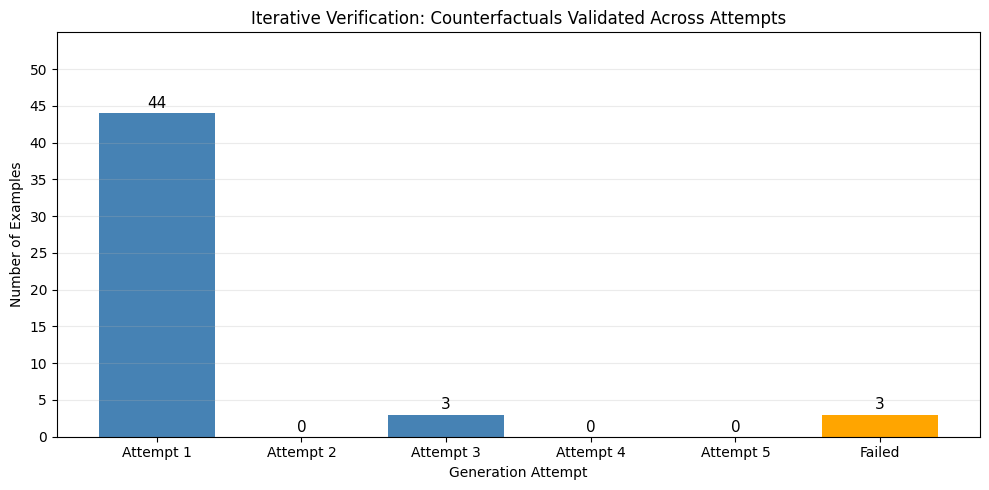

In [41]:

import matplotlib.pyplot as plt
import numpy as np

MAX_ATTEMPTS = MAX_ATTEMPTS - 1

# Count examples that first became valid at each attempt.
success_counts = (
    iterative_df[iterative_df["valid"] == True]
    ["attempts_used"]
    .value_counts()
    .reindex(range(1, MAX_ATTEMPTS + 1), fill_value=0)
)

# Count examples that remained invalid after all six attempts.
failure_count = int((iterative_df["valid"] == False).sum())

# X-axis: Attempt 1 through Attempt 6, followed by Failed.
labels = [f"Attempt {i}" for i in range(1, MAX_ATTEMPTS + 1)]
labels.append("Failed")

values = success_counts.tolist() + [failure_count]

# Plot
plt.figure(figsize=(10, 5))

bars = plt.bar(
    labels,
    values,
    color=["steelblue"] * MAX_ATTEMPTS + ["orange"]
)

# Display count above each bar.
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.3,
        str(int(height)),
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.xlabel("Generation Attempt")
plt.ylabel("Number of Examples")
plt.title("Iterative Verification: Counterfactuals Validated Across Attempts")

plt.yticks(range(0, len(iterative_df) + 1, 5))
plt.ylim(0, len(iterative_df) + 5)

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    "iterative_success_progression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# References

1. **Qwen2.5-3B-Instruct model card** : model loading and inference examples.  
   https://huggingface.co/Qwen/Qwen2.5-3B-Instruct

2. **Qwen2.5 inference documentation** : running Qwen with Transformers.  
   https://qwen.readthedocs.io/en/v2.5/inference/chat.html

3. **Hugging Face chat templates** : formatting prompts for instruction-tuned models.  
   https://huggingface.co/docs/transformers/chat_templating

4. **Hugging Face text-generation documentation** : `do_sample`, `temperature`, `top_p`, `max_new_tokens`, and `num_return_sequences`.  
   https://huggingface.co/docs/transformers/main_classes/text_generation

5. **DistilBERT SST-2 classifier** : sentiment prediction for checking candidate validity.  
   https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english

6. **Hugging Face Datasets: GLUE/SST-2** : loading the sentiment dataset.  
   https://huggingface.co/datasets/nyu-mll/glue

7. **Levenshtein distance** : background for measuring word-level edits.  
   https://en.wikipedia.org/wiki/Levenshtein_distance

## How these references relate to the baselines

- **One-shot:** Generate one rewrite using Qwen, then use the fixed sentiment classifier to check whether it reaches the target label.
- **Multi-candidate selection:** Generate five sampled candidates (`temperature=0.9`, `top_p=0.9`), classify each, and select the valid candidate with the smallest word-level edit distance. If none is valid, count the example as a failure.

#